# How does generative AI really work?

Companion notebook for the intro talk *How does generative AI really work?* It reproduces the numbers and graphs
on the slides, in talk order: next-word counting, tokens, embeddings and distances, attention, the size of GPT-2,
and how a model picks the next token.

**To run it** you only need `numpy` and `matplotlib` (any laptop or Colab, no GPU). Two optional cells compare with
the real GPT-2 model; they need internet to download it.

**Where the numbers come from.** Some numbers on the slides are made up to have a realistic shape, and each one is
marked *illustrative* below. The GPT-2 token IDs and embedding values come from the instructor's own GPT-2 run.
Everything else is computed here.

## Setup

Imports, slide colours, and the GPT-2 small sizes used on the pipeline slide ("So, what is a large language model?"):
a vocabulary of 50,257 tokens, 768 numbers per token, and 12 blocks. The helper functions used later
(`distance`, `softmax` and the three ways to pick a token) are defined here once.

In [1]:
import math
import random

import numpy as np
import matplotlib.pyplot as plt

BLUE = "#2557D6"
ORANGE = "#C2510F"
INK = "#16181D"
GREY = "#8E94A0"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

VOCAB_SIZE = 50_257   # tokens GPT-2 knows
D_MODEL = 768         # numbers per token in GPT-2 small
N_BLOCKS = 12         # transformer blocks in GPT-2 small


def distance(a, b):
    """Straight-line (Euclidean) distance between two vectors of the same length."""
    a = np.array(a)
    b = np.array(b)
    return np.sqrt(np.sum((a - b) ** 2))


def softmax(scores):
    """Turn any list of scores into probabilities that are positive and add up to 1."""
    scores = np.array(scores, dtype=float)
    exps = np.exp(scores - scores.max())   # subtracting the max avoids overflow; the result is unchanged
    return exps / exps.sum()


def greedy_pick(tokens, p_hat):
    """Always pick the single most likely token."""
    return tokens[np.argmax(p_hat)]


def random_pick(tokens, p_hat, rng):
    """Pick any token, each with its own probability."""
    return rng.choice(tokens, p=p_hat)


def top_k_pick(tokens, p_hat, k, rng):
    """Keep only the k most likely tokens, rescale them to add up to 1, then pick at random."""
    p_hat = np.array(p_hat)
    best = np.argsort(p_hat)[::-1][:k]
    kept_tokens = [tokens[i] for i in best]
    kept_p_hat = p_hat[best] / p_hat[best].sum()
    return rng.choice(kept_tokens, p=kept_p_hat)

## Title slide: "What a model thinks comes next"

The teaser shows four next-token probabilities for "…that cat jumped on the ___". We define the full
top-10 list once here; the distribution, sampling and step-4 slides reuse it.

In [2]:
# Illustrative next-token probabilities (made up, with the shape a real model gives).
next_token_probs = {"alien": 0.18, "ship": 0.12, "table": 0.08, "roof": 0.06, "ramp": 0.05,
                    "floor": 0.04, "man": 0.04, "chute": 0.03, "couch": 0.03, "hood": 0.02}

teaser = list(next_token_probs.items())[:4]
print("shown on the title slide:", teaser)
print(f"... and {VOCAB_SIZE - len(teaser):,} more tokens")

shown on the title slide: [('alien', 0.18), ('ship', 0.12), ('table', 0.08), ('roof', 0.06)]
... and 50,253 more tokens


## Hypothesis 1: keep a dictionary

Shannon's 1948 idea: count how often each 4-word phrase appears, keep the ones that start with "once upon a",
and divide each count by their total. That gives the probability of each next word.

In [3]:
# Illustrative counts (the slide says so).
ngram_counts = {"on the other hand": 48201, "once in a while": 12430, "once upon a dream": 28,
                "once upon a hill": 61, "once upon a midnight": 143, "once upon a time": 9812,
                "one of the most": 51377}

context = "once upon a"
matches = {}
for phrase, count in ngram_counts.items():
    if phrase.startswith(context + " "):
        next_word = phrase.split()[-1]
        matches[next_word] = count

total = sum(matches.values())
print("matching counts:", matches, " total =", f"{total:,}")

ngram_probs = {}
for word, count in sorted(matches.items(), key=lambda item: item[1], reverse=True):
    ngram_probs[word] = count / total
    print(f"P({word:9s}| {context}) = {count:>5,} / {total:,} = {ngram_probs[word]:.3f}")

matching counts: {'dream': 28, 'hill': 61, 'midnight': 143, 'time': 9812}  total = 10,044
P(time     | once upon a) = 9,812 / 10,044 = 0.977
P(midnight | once upon a) =   143 / 10,044 = 0.014
P(hill     | once upon a) =    61 / 10,044 = 0.006
P(dream    | once upon a) =    28 / 10,044 = 0.003


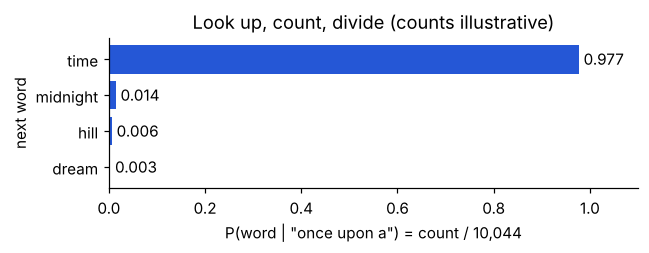

In [4]:
words = list(ngram_probs)
probs = list(ngram_probs.values())

fig, ax = plt.subplots(figsize=(6, 2.4))
ax.barh(words, probs, color=BLUE)
for i, p in enumerate(probs):
    ax.text(p + 0.01, i, f"{p:.3f}", va="center")
ax.invert_yaxis()   # most likely word on top
ax.set_xlim(0, 1.1)
ax.set_xlabel(f'P(word | "{context}") = count / {total:,}')
ax.set_ylabel("next word")
ax.set_title("Look up, count, divide (counts illustrative)")
plt.tight_layout()
plt.show()

## Test: longer context, fewer matches

The longer the context, the fewer times we have seen it, until we have never seen it at all.
The reason: the number of possible 20-word sequences from a 50,000-word vocabulary, 50,000²⁰ ≈ 10⁹⁴, is far more
than the roughly 10⁸⁰ atoms in the observable universe.

In [5]:
# Illustrative counts (the slide says so).
context_counts = {
    "the": 1_200_000_000,
    "on the": 38_000_000,
    "jumped on the": 41_000,
    "cat jumped on the": 1_900,
    "that cat jumped on the": 210,
    "one time, that cat jumped on the": 3,
    "Actually, one time, that cat jumped on the": 0,
    "Tom loved playing around the fence. Actually, one time, that cat jumped on the": 0,
}
for text, count in context_counts.items():
    print(f"{count:>13,}  | {text} ___")

# Work with log10 so the huge number stays readable.
exponent = 20 * math.log10(50_000)
print(f"\n50,000^20 = 10^{exponent:.2f}, about 10^{round(exponent)}")
print(f"that is {round(exponent) - 80} orders of magnitude more than the ~10^80 atoms in the universe")

1,200,000,000  | the ___
   38,000,000  | on the ___
       41,000  | jumped on the ___
        1,900  | cat jumped on the ___
          210  | that cat jumped on the ___
            3  | one time, that cat jumped on the ___
            0  | Actually, one time, that cat jumped on the ___
            0  | Tom loved playing around the fence. Actually, one time, that cat jumped on the ___

50,000^20 = 10^93.98, about 10^94
that is 14 orders of magnitude more than the ~10^80 atoms in the universe


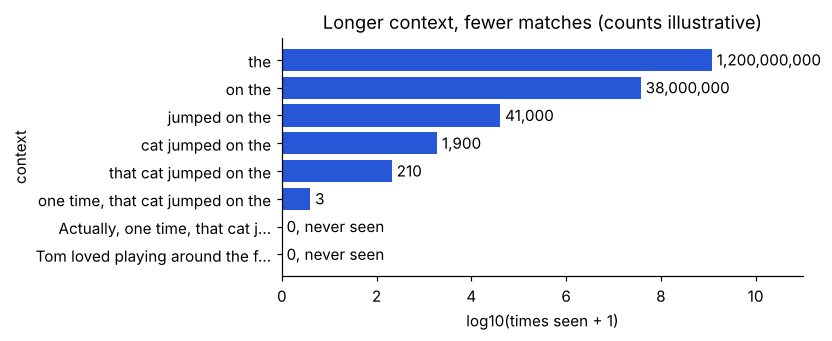

In [6]:
labels = []
for text in context_counts:
    if len(text) > 34:
        text = text[:30] + "…"   # keep long labels short but still different
    labels.append(text)
counts = np.array(list(context_counts.values()))
heights = np.log10(counts + 1)   # +1 so that a count of 0 is drawn as 0
colours = [BLUE if count > 0 else ORANGE for count in counts]

fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.barh(labels, heights, color=colours)
for i, count in enumerate(counts):
    label = f"{count:,}" if count > 0 else "0, never seen"
    ax.text(heights[i] + 0.1, i, label, va="center")
ax.invert_yaxis()
ax.set_xlim(0, 11)
ax.set_xlabel("log10(times seen + 1)")
ax.set_ylabel("context")
ax.set_title("Longer context, fewer matches (counts illustrative)")
plt.tight_layout()
plt.show()

## Step 1: text becomes tokens

GPT-2 splits text into 25 tokens and gives each one an ID. A `·` marks a leading space, so "The" at the start (464)
and "·The" after a space (383) are different tokens, and "thud" is split into "·th" + "ud".
The IDs come from the instructor's GPT-2 run, which spelled the sentence "came down the **shoot**";
the other slides say "chute".

In [7]:
# Tokens and IDs from the instructor's GPT-2 run.
tokens_with_ids = [("The", 464), ("·spaceship", 40663), ("·landed", 11406), ("·with", 351), ("·a", 257),
                   ("·th", 294), ("ud", 463), (".", 13), ("·The", 383), ("·green", 4077), ("·men", 1450),
                   ("·came", 1625), ("·down", 866), ("·the", 262), ("·shoot", 2686), ("·and", 290),
                   ("·before", 878), ("·I", 314), ("·knew", 2993), ("·it", 340), ("·that", 326),
                   ("·cat", 3797), ("·jumped", 11687), ("·on", 319), ("·the", 262)]
instructor_ids = [token_id for token, token_id in tokens_with_ids]

print("number of tokens:", len(tokens_with_ids))
print("IDs:", instructor_ids)

number of tokens: 25
IDs: [464, 40663, 11406, 351, 257, 294, 463, 13, 383, 4077, 1450, 1625, 866, 262, 2686, 290, 878, 314, 2993, 340, 326, 3797, 11687, 319, 262]


**Optional check with the real GPT-2 tokenizer** (needs internet). It should print `matches the slide: True` for
"shoot", and it also shows the "chute" version.

In [ ]:
try:
    import tiktoken
except ImportError:
    %pip install -q tiktoken
    import tiktoken

encoder = tiktoken.get_encoding("gpt2")
for word in ["shoot", "chute"]:
    sentence = f"The spaceship landed with a thud. The green men came down the {word} and before I knew it that cat jumped on the"
    ids = encoder.encode(sentence)
    pieces = [encoder.decode([token_id]).replace(" ", "·") for token_id in ids]
    print(f"{word}: {len(ids)} tokens")
    print(list(zip(pieces, ids)))
    if word == "shoot":
        print("matches the slide:", ids == instructor_ids)

## Question: what is a vector?

A vector is a list of numbers. [3, 2] is a point, or an arrow 3 right and 2 up.

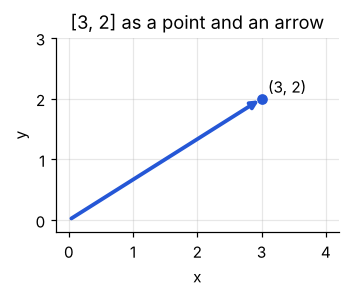

In [8]:
fig, ax = plt.subplots(figsize=(3.4, 2.8))
ax.annotate("", xy=(3, 2), xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=BLUE, lw=2.5))
ax.plot(3, 2, "o", color=BLUE)
ax.text(3.1, 2.1, "(3, 2)")
ax.set_xlim(-0.2, 4.2)
ax.set_ylim(-0.2, 3)
ax.grid(alpha=0.3)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("[3, 2] as a point and an arrow")
plt.tight_layout()
plt.show()

## What is an embedding? (personality test)

Tom's five personality scores (0 to 100) become a vector by rescaling each one with (score − 50) / 50,
so 50 is average (0), 100 is +1 and 0 is −1.

In [9]:
TRAITS = ["Openness", "Agreeableness", "Conscientiousness", "Neg. emotionality", "Extraversion"]
tom_scores = np.array([79, 75, 42, 50, 59])

tom_vector = (tom_scores - 50) / 50
for trait, score, value in zip(TRAITS, tom_scores, tom_vector):
    print(f"{trait:18s} {score:3d}/100  ->  {value:+.2f}")

Openness            79/100  ->  +0.58
Agreeableness       75/100  ->  +0.50
Conscientiousness   42/100  ->  -0.16
Neg. emotionality   50/100  ->  +0.00
Extraversion        59/100  ->  +0.18


## Who is most like Tom?

The vectors for Tom, Marvin and Janet, drawn as bars: blue above average, orange below.

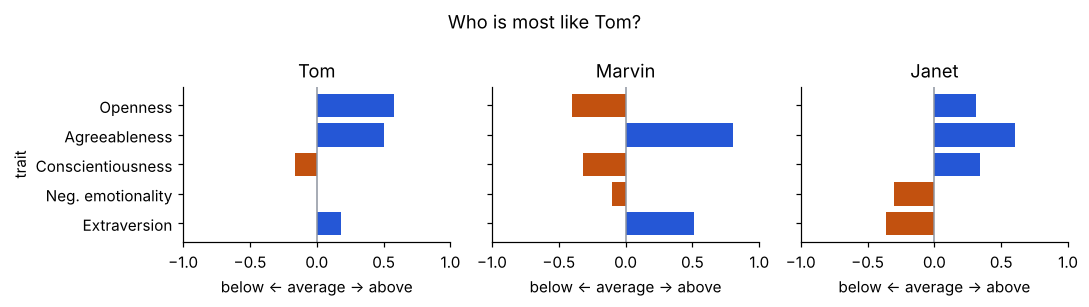

In [10]:
people = {
    "Tom":    np.array([0.58, 0.50, -0.16, 0.00, 0.18]),
    "Marvin": np.array([-0.40, 0.80, -0.32, -0.10, 0.51]),
    "Janet":  np.array([0.31, 0.60, 0.34, -0.30, -0.36]),
}
tom = people["Tom"]
marvin = people["Marvin"]
janet = people["Janet"]

fig, axs = plt.subplots(1, 3, figsize=(10, 2.8), sharey=True)
for ax, (name, vector) in zip(axs, people.items()):
    colours = [BLUE if value > 0 else ORANGE for value in vector]
    ax.barh(TRAITS, vector, color=colours)
    ax.axvline(0, color=GREY, lw=1)
    ax.invert_yaxis()
    ax.set_xlim(-1, 1)
    ax.set_xlabel("below ← average → above")
    ax.set_title(name)
axs[0].set_ylabel("trait")
fig.suptitle("Who is most like Tom?")
plt.tight_layout()
plt.show()

## People as points in space

With openness only (1 dimension), Janet sits right next to Tom and Marvin is far away. Adding agreeableness
(2 dimensions) moves everyone up, but Janet is still closest.

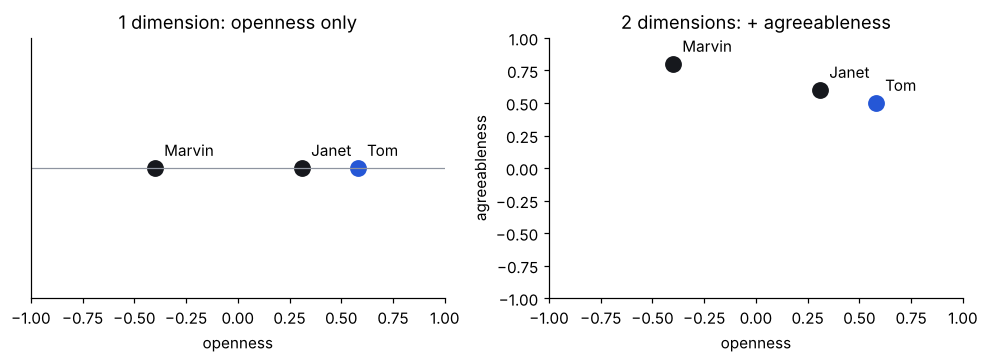

In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.4))
for name, vector in people.items():
    colour = BLUE if name == "Tom" else INK
    ax1.plot(vector[0], 0, "o", ms=10, color=colour)
    ax1.annotate(name, (vector[0], 0), xytext=(6, 8), textcoords="offset points")
    ax2.plot(vector[0], vector[1], "o", ms=10, color=colour)
    ax2.annotate(name, (vector[0], vector[1]), xytext=(6, 8), textcoords="offset points")

ax1.axhline(0, color=GREY, lw=0.8)
ax1.set_xlim(-1, 1)
ax1.set_yticks([])
ax1.set_xlabel("openness")
ax1.set_title("1 dimension: openness only")

ax2.set_xlim(-1, 1)
ax2.set_ylim(-1, 1)
ax2.set_xlabel("openness")
ax2.set_ylabel("agreeableness")
ax2.set_title("2 dimensions: + agreeableness")
plt.tight_layout()
plt.show()

## Distance in any number of dimensions

The same formula works in any number of dimensions: square the gap in each trait, add them up, take the square root.
We use the first *n* traits for *n* dimensions. Janet stays closer to Tom than Marvin does every time.

Slide check: the 2D Tom → Marvin distance is 1.025, which rounds to **1.02**; the slide shows **1.03**.

In [12]:
print("dims   Tom→Marvin   Tom→Janet")
for n in [1, 2, 3, 5]:
    to_marvin = distance(tom[:n], marvin[:n])
    to_janet = distance(tom[:n], janet[:n])
    print(f"{n:>4}   {to_marvin:10.3f}   {to_janet:9.3f}    (rounded: {to_marvin:.2f} / {to_janet:.2f})")

# Show the formula for Tom → Janet, one dimension at a time.
gaps = np.abs(tom - janet)
print()
for n in [1, 2, 3, 5]:
    terms = " + ".join(f"{gap:.2f}²" for gap in gaps[:n])
    print(f"{n}D: d = √( {terms} ) = {distance(tom[:n], janet[:n]):.2f}")

dims   Tom→Marvin   Tom→Janet
   1        0.980       0.270    (rounded: 0.98 / 0.27)
   2        1.025       0.288    (rounded: 1.02 / 0.29)
   3        1.037       0.577    (rounded: 1.04 / 0.58)
   5        1.093       0.845    (rounded: 1.09 / 0.85)

1D: d = √( 0.27² ) = 0.27
2D: d = √( 0.27² + 0.10² ) = 0.29
3D: d = √( 0.27² + 0.10² + 0.50² ) = 0.58
5D: d = √( 0.27² + 0.10² + 0.50² + 0.30² + 0.54² ) = 0.85


The four graphs on the slide, Tom → Janet, drawn to scale. In 3D the axes are openness (across),
conscientiousness (depth) and agreeableness (up).

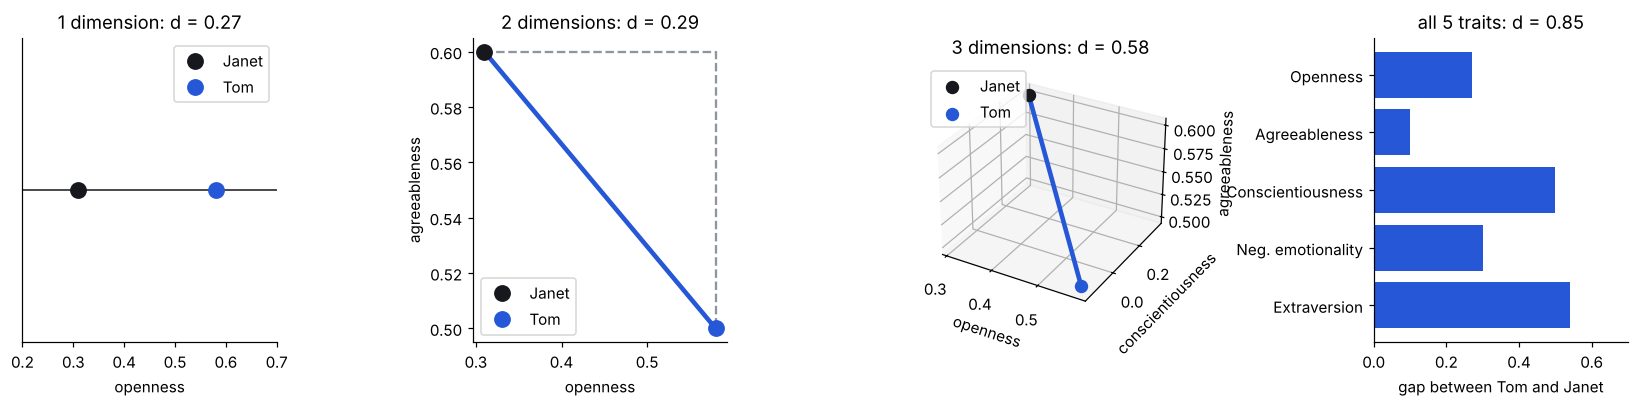

In [13]:
fig = plt.figure(figsize=(15, 3.8))

# 1 dimension
ax = fig.add_subplot(1, 4, 1)
ax.axhline(0, color=INK, lw=1)
ax.plot(janet[0], 0, "o", ms=10, color=INK, label="Janet")
ax.plot(tom[0], 0, "o", ms=10, color=BLUE, label="Tom")
ax.set_xlim(0.2, 0.7)
ax.set_yticks([])
ax.set_xlabel("openness")
ax.set_title(f"1 dimension: d = {distance(tom[:1], janet[:1]):.2f}")
ax.legend()

# 2 dimensions: the distance is the long side of a right triangle
ax = fig.add_subplot(1, 4, 2)
ax.plot([janet[0], tom[0], tom[0]], [janet[1], janet[1], tom[1]], "--", color=GREY)
ax.plot([janet[0], tom[0]], [janet[1], tom[1]], color=BLUE, lw=3)
ax.plot(janet[0], janet[1], "o", ms=10, color=INK, label="Janet")
ax.plot(tom[0], tom[1], "o", ms=10, color=BLUE, label="Tom")
ax.set_xlabel("openness")
ax.set_ylabel("agreeableness")
ax.set_title(f"2 dimensions: d = {distance(tom[:2], janet[:2]):.2f}")
ax.legend()

# 3 dimensions
ax = fig.add_subplot(1, 4, 3, projection="3d")
ax.plot([janet[0], tom[0]], [janet[2], tom[2]], [janet[1], tom[1]], color=BLUE, lw=3)
ax.scatter(janet[0], janet[2], janet[1], s=60, color=INK, label="Janet")
ax.scatter(tom[0], tom[2], tom[1], s=60, color=BLUE, label="Tom")
ax.set_xlabel("openness")
ax.set_ylabel("conscientiousness")
ax.set_zlabel("agreeableness")
ax.set_title(f"3 dimensions: d = {distance(tom[:3], janet[:3]):.2f}")
ax.legend(loc="upper left")

# 5 dimensions cannot be drawn, so show the gap in each trait
ax = fig.add_subplot(1, 4, 4)
ax.barh(TRAITS, gaps, color=BLUE)
ax.invert_yaxis()
ax.set_xlim(0, 0.7)
ax.set_xlabel("gap between Tom and Janet")
ax.set_title(f"all 5 traits: d = {distance(tom, janet):.2f}")
plt.tight_layout()
plt.show()

## Words need numbers too, and semantic math

Nothing to compute here: the word positions and the 2D "meaning as location" sketches on these slides are drawn by hand.
The analogies (king − man + woman ≈ queen, Paris − France + Germany ≈ Berlin) are the well-known word2vec results
(Mikolov et al., 2013), and doctor − man + woman ≈ nurse is the embedding-bias example from Bolukbasi et al. (2016).

## Step 2: tokens become vectors

GPT-2 small stores one row of 768 numbers for each of its 50,257 tokens. The slide shows the first and last three
numbers of a few rows; these values come from the instructor's GPT-2 run.

In [14]:
# GPT-2 small embedding rows from the instructor's run: numbers 1, 2, 3, 766, 767, 768 of each row.
embedding_rows = {
    0:     ("!",             [-0.1101, -0.0393, 0.0331, -0.1364, 0.0151, 0.0453]),
    1:     ('"',             [0.0403, -0.0486, 0.0462, 0.0861, 0.0025, 0.0432]),
    2:     ("#",             [-0.1275, 0.0479, 0.1841, 0.0899, -0.1297, -0.0879]),
    464:   ("The",           [-0.0686, -0.0203, 0.0645, 0.0639, -0.0100, 0.0031]),
    50254: ("·informants",   [-0.0445, -0.0548, 0.0123, 0.1044, 0.0978, -0.0695]),
    50255: ("·gazed",        [0.1860, 0.0167, 0.0461, -0.0963, 0.0785, -0.0225]),
    50256: ("<|endoftext|>", [0.0514, -0.0277, 0.0499, 0.0070, 0.1552, 0.1207]),
}

print(f"table: {VOCAB_SIZE:,} rows x {D_MODEL} columns = {VOCAB_SIZE * D_MODEL:,} numbers")
print(f"our 25-token sentence becomes a 25 x {D_MODEL} grid = {25 * D_MODEL:,} numbers")
for row, (token, values) in embedding_rows.items():
    first = " ".join(f"{x:+.4f}" for x in values[:3])
    last = " ".join(f"{x:+.4f}" for x in values[3:])
    print(f"{row:>6,} {token:14s} {first}  …  {last}")

table: 50,257 rows x 768 columns = 38,597,376 numbers
our 25-token sentence becomes a 25 x 768 grid = 19,200 numbers
     0 !              -0.1101 -0.0393 +0.0331  …  -0.1364 +0.0151 +0.0453
     1 "              +0.0403 -0.0486 +0.0462  …  +0.0861 +0.0025 +0.0432
     2 #              -0.1275 +0.0479 +0.1841  …  +0.0899 -0.1297 -0.0879
   464 The            -0.0686 -0.0203 +0.0645  …  +0.0639 -0.0100 +0.0031
50,254 ·informants    -0.0445 -0.0548 +0.0123  …  +0.1044 +0.0978 -0.0695
50,255 ·gazed         +0.1860 +0.0167 +0.0461  …  -0.0963 +0.0785 -0.0225
50,256 <|endoftext|>  +0.0514 -0.0277 +0.0499  …  +0.0070 +0.1552 +0.1207


**Optional check with the real GPT-2 embedding table** (needs internet; uses `torch` and `transformers`,
both preinstalled on Colab).

In [ ]:
from transformers import GPT2Model

model = GPT2Model.from_pretrained("gpt2")
embedding_table = model.wte.weight.detach().numpy()
print("table shape:", embedding_table.shape)

shown_columns = [0, 1, 2, 765, 766, 767]   # numbers 1-3 and 766-768, counted from 0
for row, (token, values) in embedding_rows.items():
    real_values = embedding_table[row, shown_columns].round(4)
    print(row, token, real_values, "matches the slide:", np.allclose(real_values, values, atol=1e-4))

## Step 3: attention

The last "the" gives every token a match score. Dividing by 8 (the square root of the 64 numbers per attention head)
and applying softmax turns the scores into weights that add up to 1. The new "the" is the weighted mix of all 25
tokens. This slide spells the sentence "chute".

In [15]:
# Illustrative match scores (the slide says so); every other token scores 18.
attention_scores = {"·spaceship": 40, "·landed": 33, "·green": 34, "·men": 37, "·chute": 32,
                    "·cat": 31, "·jumped": 29, "·th": 24, "ud": 24}
sentence_tokens = ["The", "·spaceship", "·landed", "·with", "·a", "·th", "ud", ".", "·The", "·green", "·men",
                   "·came", "·down", "·the", "·chute", "·and", "·before", "·I", "·knew", "·it", "·that",
                   "·cat", "·jumped", "·on", "·the"]

scores = np.array([attention_scores.get(token, 18) for token in sentence_tokens])
scores[-1] = 26   # the query token "the" itself (also illustrative)
weights = softmax(scores / 8)

shown = ["·spaceship", "·landed", "·green", "·men", "·cat"]
shown_total = 0
for token in shown:
    i = sentence_tokens.index(token)
    shown_total += weights[i]
    print(f"{token:12s} score {scores[i]}  ->  weight {weights[i]:.3f}")
print(f"20 others          ->  weight {1 - shown_total:.3f}")
print("sum of all 25 weights =", round(weights.sum(), 6))

·spaceship   score 40  ->  weight 0.203
·landed      score 33  ->  weight 0.085
·green       score 34  ->  weight 0.096
·men         score 37  ->  weight 0.140
·cat         score 31  ->  weight 0.066
20 others          ->  weight 0.411
sum of all 25 weights = 1.0


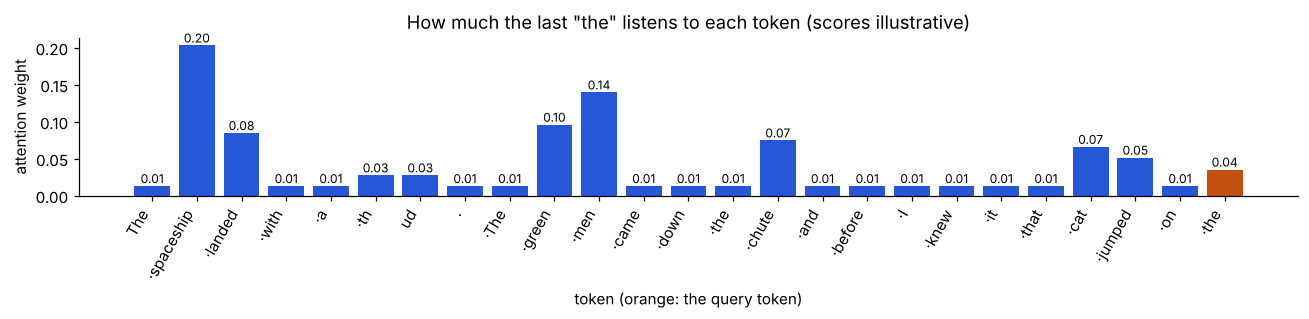

In [16]:
colours = [BLUE] * (len(weights) - 1) + [ORANGE]   # orange = the query token

fig, ax = plt.subplots(figsize=(12, 3))
ax.bar(range(len(weights)), weights, color=colours)
ax.set_xticks(range(len(weights)))
ax.set_xticklabels(sentence_tokens, rotation=60, ha="right")
for i, weight in enumerate(weights):
    ax.text(i, weight + 0.004, f"{weight:.2f}", ha="center", fontsize=8)
ax.set_xlabel("token (orange: the query token)")
ax.set_ylabel("attention weight")
ax.set_title('How much the last "the" listens to each token (scores illustrative)')
plt.tight_layout()
plt.show()

## Combine, untangle, repeat

Counting the learned numbers in GPT-2 small from its standard layer shapes gives about 124 million,
and about ⅔ of each block sits in the MLP (768 → 3,072 → 768).

In [17]:
hidden = 4 * D_MODEL
context_length = 1024

# Each linear layer has (inputs x outputs) weights plus one bias per output.
mlp = (D_MODEL * hidden + hidden) + (hidden * D_MODEL + D_MODEL)
attention = (D_MODEL * 3 * D_MODEL + 3 * D_MODEL) + (D_MODEL * D_MODEL + D_MODEL)   # q, k, v, then output
layer_norms = 2 * (2 * D_MODEL)                                                     # two per block, scale + shift
block = mlp + attention + layer_norms

parameter_split = {
    "token embeddings": VOCAB_SIZE * D_MODEL,
    "position embeddings": context_length * D_MODEL,
    "attention (12 blocks)": N_BLOCKS * attention,
    "MLP (12 blocks)": N_BLOCKS * mlp,
    "layer norms": N_BLOCKS * layer_norms + 2 * D_MODEL,   # + one final layer norm
}
total = sum(parameter_split.values())

print(f"MLP hidden size {hidden:,}; MLP share of a block = {mlp / block:.3f} (about 2/3)")
for part, count in parameter_split.items():
    print(f"{part:22s} {count:>12,}")
print(f"{'total':22s} {total:>12,} (about 124 million)")

MLP hidden size 3,072; MLP share of a block = 0.666 (about 2/3)
token embeddings         38,597,376
position embeddings         786,432
attention (12 blocks)    28,348,416
MLP (12 blocks)          56,669,184
layer norms                  38,400
total                   124,439,808 (about 124 million)


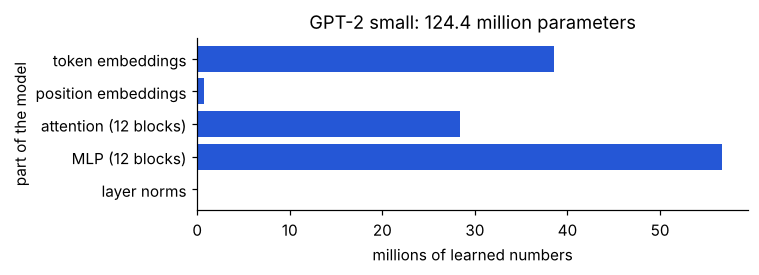

In [18]:
fig, ax = plt.subplots(figsize=(7, 2.6))
ax.barh(list(parameter_split), np.array(list(parameter_split.values())) / 1e6, color=BLUE)
ax.invert_yaxis()
ax.set_xlabel("millions of learned numbers")
ax.set_ylabel("part of the model")
ax.set_title(f"GPT-2 small: {total / 1e6:.1f} million parameters")
plt.tight_layout()
plt.show()

## Step 4: a probability for every token

The model outputs a probability for all 50,257 tokens. The slide shows 180 of them: the top 10 from above,
16 hand-picked small ones, and filler words with tiny random probabilities (seed 7). A few tokens take most of the
chance; most get almost nothing ("≈ 0").

In [19]:
# Illustrative small probabilities for 16 more tokens.
mid_probs = {"ground": 0.012, "spaceship": 0.011, "bed": 0.009, "counter": 0.008, "creature": 0.007,
             "car": 0.006, "fence": 0.005, "green": 0.004, "robot": 0.004, "door": 0.003, "top": 0.003,
             "other": 0.003, "back": 0.002, "cat": 0.002, "dog": 0.002, "window": 0.002}

filler_words = """the , . of and to a in is that for it as was with be by on not he I this are or his from at
which but have an they you were her she there one all we their has been would will more if no when what so up out
about who them do can into than then some time could two these may like other only new now over also any after first
my years just most made people where very me our through back much should well because how even many before must
right still being same here own those while state down world great might under last never life again off city day
old another long year place both however around end without every few came high small large part best good number
home already house quantum banana 1997 Paris Tuesday ## ing ed ly er !! ? ; : ( ) - — ' " 0 1 2 42 2026 € $ %""".split()
filler_words = [w for w in filler_words if w not in next_token_probs and w not in mid_probs]

N_TILES = 180
random.seed(7)
wall_tokens = list(next_token_probs) + list(mid_probs)
wall_tokens += filler_words[:N_TILES - len(wall_tokens)]
random.shuffle(wall_tokens)

# Filler words get an illustrative probability between 10^-7 and 10^-3.3.
wall_probs = {}
for token in wall_tokens:
    if token in next_token_probs:
        wall_probs[token] = next_token_probs[token]
    elif token in mid_probs:
        wall_probs[token] = mid_probs[token]
    else:
        wall_probs[token] = 10 ** random.uniform(-7, -3.3)


def tile_label(p):
    """Short probability label for a tile; anything below 0.0001 is shown as '≈ 0'."""
    if p < 0.0001:
        return "≈ 0"
    if p >= 0.01:
        return f"{p:.2f}"
    if p >= 0.001:
        return f"{p:.3f}"
    return f"{p:.4f}"


labels = [tile_label(wall_probs[token]) for token in wall_tokens]
print(f"tokens on the wall: {len(wall_tokens)} | ... {VOCAB_SIZE - len(wall_tokens):,} more")
print("first 6 tiles:")
for token, label in zip(wall_tokens[:6], labels[:6]):
    print(f"   {token:8s} {label:>6s}   (p = {round(wall_probs[token], 6)})")
print(f"probability on the wall: {sum(wall_probs.values()):.3f}  (the other tokens share the rest)")
print('tiles shown as "≈ 0":', labels.count("≈ 0"))

tokens on the wall: 180 | ... 50,077 more
first 6 tiles:
   will        ≈ 0   (p = 1.7e-05)
   top       0.003   (p = 0.003)
   of          ≈ 0   (p = 0.0)
   through     ≈ 0   (p = 1.3e-05)
   be          ≈ 0   (p = 1e-05)
   can      0.0003   (p = 0.000324)
probability on the wall: 0.742  (the other tokens share the rest)
tiles shown as "≈ 0": 127


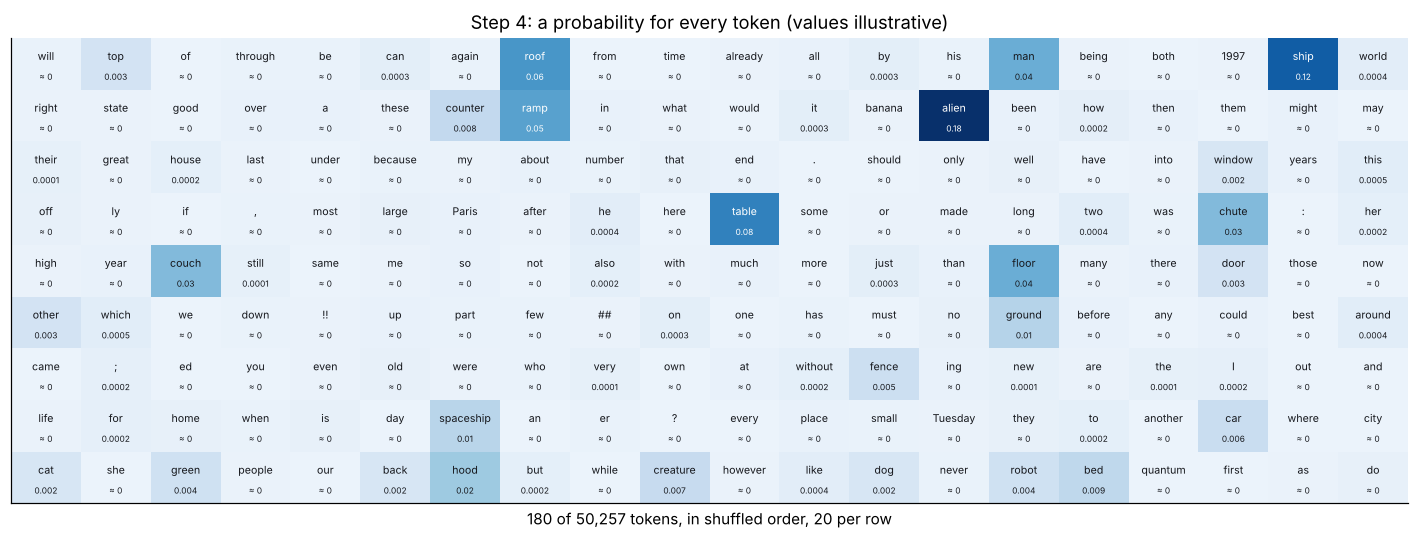

In [20]:
TILES_PER_ROW = 20
# Darker tile = more likely; the square root makes small values visible.
shade = np.array([math.sqrt(min(1, wall_probs[token] / 0.18)) for token in wall_tokens])
shade = shade.reshape(-1, TILES_PER_ROW)

fig, ax = plt.subplots(figsize=(13, 5))
ax.imshow(0.06 + 0.94 * shade, cmap="Blues", vmin=0, vmax=1, aspect="auto")
for k, token in enumerate(wall_tokens):
    row, col = divmod(k, TILES_PER_ROW)
    text_colour = "white" if shade[row, col] > 0.5 else INK
    ax.text(col, row - 0.15, token, ha="center", va="center", fontsize=7, color=text_colour)
    ax.text(col, row + 0.25, labels[k], ha="center", va="center", fontsize=5.5, color=text_colour)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel(f"{N_TILES} of {VOCAB_SIZE:,} tokens, in shuffled order, {TILES_PER_ROW} per row")
ax.set_title("Step 4: a probability for every token (values illustrative)")
plt.tight_layout()
plt.show()

## LLMs learn a distribution

The top 10 tokens for "…that cat jumped on the ___" hold about 65% of the probability; the other 50,247 tokens share
the rest (the grey tail).

top-10 share = 0.65 (about 65%) | ... 50,247 more


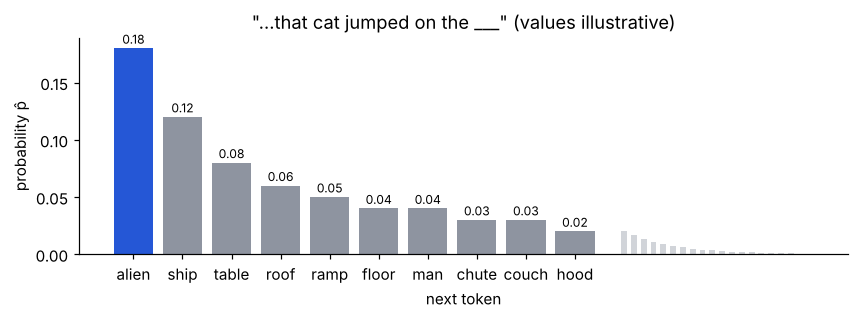

In [21]:
top_tokens = list(next_token_probs)
top_p_hat = np.array(list(next_token_probs.values()))
top_share = top_p_hat.sum()
print(f"top-10 share = {top_share:.2f} (about {top_share:.0%}) | ... {VOCAB_SIZE - len(top_tokens):,} more")


def plot_next_tokens(ax, highlighted, title):
    """Bar chart of the top-10 next tokens, with the chosen candidates in blue and a grey tail."""
    colours = [BLUE if token in highlighted else GREY for token in top_tokens]
    ax.bar(top_tokens, top_p_hat, color=colours)
    for i, p in enumerate(top_p_hat):
        ax.text(i, p + 0.004, f"{p:.2f}", ha="center", fontsize=8)
    tail_x = np.arange(10, 14, 0.2)
    ax.bar(tail_x, 0.02 * 0.82 ** np.arange(len(tail_x)), width=0.12, color=GREY, alpha=0.4)   # sketch of the long tail
    ax.set_xlabel("next token")
    ax.set_ylabel("probability p̂")
    ax.set_title(title)


fig, ax = plt.subplots(figsize=(8, 3))
plot_next_tokens(ax, ["alien"], '"…that cat jumped on the ___" (values illustrative)')
plt.tight_layout()
plt.show()

## Which token do we pick? Three ways to choose

Greedy always takes "alien". Random can pick any of the 50,257 tokens. Top-k (k = 5) picks at random among the
5 most likely. The example continuations on the slide were written by hand.

Greedy               candidates: ['alien']


Random (all 50,257)  candidates: ['alien', 'ship', 'table', 'roof', 'ramp', 'floor', 'man', 'chute', 'couch', 'hood']
Top-k (k = 5)        candidates: ['alien', 'ship', 'table', 'roof', 'ramp']


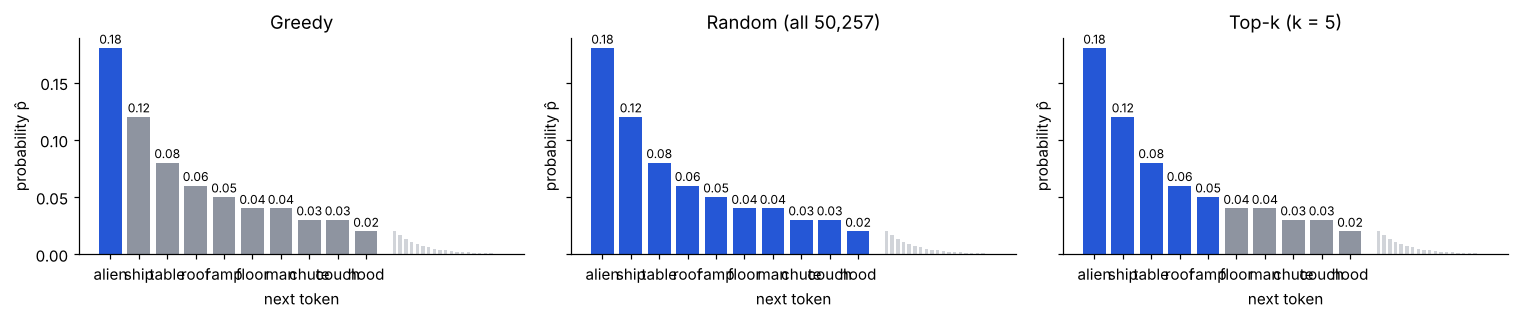

In [22]:
K = 5
candidates = {
    "Greedy": top_tokens[:1],
    "Random (all 50,257)": top_tokens,
    f"Top-k (k = {K})": top_tokens[:K],
}

fig, axs = plt.subplots(1, 3, figsize=(14, 3), sharey=True)
for ax, (name, chosen) in zip(axs, candidates.items()):
    plot_next_tokens(ax, chosen, name)
    print(f"{name:20s} candidates: {chosen}")
plt.tight_layout()
plt.show()

Now actually pick tokens with the three helper functions from the setup. For random picking, the 50,247 tokens we
do not list are grouped into one "(other)" entry holding the remaining 0.35, so the probabilities add up to 1.
Greedy and top-k only need the top 10, because every unlisted token is less likely than these.
The fixed seed makes the picks the same every run.

In [23]:
all_tokens = top_tokens + ["(other)"]
all_p_hat = np.append(top_p_hat, 1 - top_share)

rng = np.random.default_rng(seed=0)
print("greedy:", [greedy_pick(top_tokens, top_p_hat) for _ in range(8)])
print("random:", [str(random_pick(all_tokens, all_p_hat, rng)) for _ in range(8)])
print("top-5: ", [str(top_k_pick(top_tokens, top_p_hat, K, rng)) for _ in range(8)])

greedy: ['alien', 'alien', 'alien', 'alien', 'alien', 'alien', 'alien', 'alien']
random: ['hood', 'ship', 'alien', 'alien', '(other)', '(other)', 'couch', '(other)']
top-5:  ['ship', 'ramp', 'roof', 'alien', 'roof', 'alien', 'table', 'alien']


## Test again: 76 years later

From Shannon's N-grams (1948) to GPT-4o (2024), with almost all of the progress since word2vec (2013).
GPT-4o's answer "alien." on the slide is a screenshot from the instructor's ChatGPT run.

In [24]:
print("2024 - 1948 =", 2024 - 1948, "years")
print("2024 - 2013 =", 2024 - 2013, "years")

2024 - 1948 = 76 years
2024 - 2013 = 11 years
